### 다중 분류 실습 문제

## Intel Image Dataset
: 자연 풍경 및 도시 환경 사진을 6개 클래스로 분류하는 이미지 데이터셋

- 학습데이터 : 약 14,000
- 테스트 데이터 : 약 3,000
- 예측용 데이터 : 약 7,000
- 이미지 크기 : 150 x 150(컬러 이미지)
- 입력 이미지 : RGB 이미지 (64× 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 3,072
- 출력 클래스: 6개

| 클래스 이름 | 의미 |
|:---:|:---|
| `buildings` | 건물 |
| `forest` | 숲 |
| `glacier` | 빙하 |
| `mountain` | 산 |
| `sea` | 바다 |
| `street` | 거리 |

#### STEP 1. 데이터 불러오기 및 전처리

**실습 조건**
- `torchvision.datasets.ImageFolder`를 이용해 학습 데이터와 테스트 데이터를 불러온다.
- 이미지를 `(64, 64)` 크기로 통일한다.
- `transforms.ToTensor()`를 이용해 Tensor로 변환한다.
- RGB 이미지이므로 이미지 한 장의 형태는 `[3, 64, 64]`이다.
- `ImageFolder`가 부여한 클래스 인덱스와 클래스 이름을 확인한다.
- 학습 데이터와 테스트 데이터의 클래스 순서가 같은지 확인한다.
- 데이터 개수와 첫 번째 이미지의 shape을 출력한다.

In [54]:
# 데이터를 다운로드 하려면 설치 필요
# %pip install kagglehub

In [1]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import shutil
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [3]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = "MLP"
dataset = "intel_image"

os.makedirs('results', exist_ok=True)

save_model_path = f'results/{model_type}_{dataset}.pt'

In [4]:
# 저장 위치
data_dir = 'data/intel_image'

if os.path.exists(os.path.join(data_dir, 'seg_train')):
  print('이미 데이터가 존재합니다')
else :
  # 1. KaggleHub에서 데이터셋 가져오기
  dataset_path = kagglehub.dataset_download(
      "puneet6060/intel-image-classification"
  )

  print("Kaggle 데이터 위치:", dataset_path)

  # 2. Google Drive에 복사
  os.makedirs(data_dir, exist_ok=True)

  shutil.copytree(
      dataset_path,
      data_dir,
      dirs_exist_ok=True
  )

  print("저장 완료!")

이미 데이터가 존재합니다


In [5]:
# 이미지 전처리 및 Totensor() 설정
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
train_DS = datasets.ImageFolder(
    root=f'{data_dir}/seg_train/seg_train',
    transform=transform
)

test_DS = datasets.ImageFolder(
    root=f'{data_dir}/seg_test/seg_test',
    transform=transform
)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

In [59]:
print("클래스:", train_DS.classes)
print("클래스 인덱스:", train_DS.class_to_idx)
print("학습 데이터 개수:", len(train_DS))
print("테스트 데이터 개수:", len(test_DS))

클래스: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
클래스 인덱스: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
학습 데이터 개수: 3521
테스트 데이터 개수: 2996


#### STEP 2. DataLoader 생성 및 데이터 확인

**실습 조건**
- 학습률(LR): `1e-3`
- Epoch: 10 이상
- Batch size: 32
- Optimizer: Adam
- Loss function: CrossEntropyLoss
- 학습 데이터는 `shuffle=True`, 테스트 데이터는 `shuffle=False`로 설정한다.
- 첫 번째 배치의 `x_batch`, `y_batch` shape을 확인한다.
- 이미지를 시각화하고 이미지의 클래스 이름을 표시한다.

x_batch: torch.Size([32, 3, 64, 64])
sea


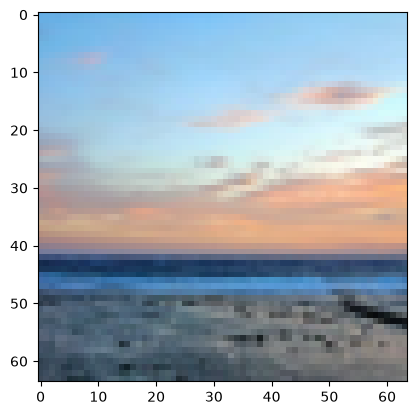

In [6]:
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch = next(iter(train_DL))
print("x_batch:", x_batch.shape)  # [batch_size, 3, 64, 64]

# 이미지 1장
plt.imshow(x_batch[0].permute(1,2,0))
print(test_DS.classes[y_batch[0]])

#### STEP 3. MLP 모델 만들기

**모델 조건**

- 입력 이미지 크기: `[3, 64, 64]`
- `torch.flatten(x, start_dim=1)`을 이용해 배치 차원은 유지하고 나머지 차원을 펼친다.
- 입력 특징 수: `3 × 64 × 64`<br><br>

- 3가지의 모델 정의하기
    1. 은닉층 노드 수: 30개
    2. 은닉층 노드 수: 100개
    3. 여러개의 은닉층

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(
            nn.Linear(3*64*64, 30),
            nn.BatchNorm1d(30),
            nn.ReLU(),
            nn.Linear(30, 6)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

class MLP_shallow(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(nn.Linear(3*64*64, 512),
                                    nn.BatchNorm1d(512),
                                    nn.ReLU(),

                                    nn.Linear(512, 256),
                                    nn.BatchNorm1d(256),
                                    nn.ReLU(),

                                    nn.Linear(256, 128),
                                    nn.BatchNorm1d(128),
                                    nn.ReLU(),

                                    nn.Linear(128, 6)
                                    )
    def forward(self,x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x

class MLP_drop(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(
            nn.Linear(3*64*64, 30),
            nn.BatchNorm1d(30),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(30, 6)
        )

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear(x)
        return x


In [8]:
model = globals()[model_type]().to(DEVICE)
print(model)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=12288, out_features=30, bias=True)
    (1): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=30, out_features=6, bias=True)
  )
)


#### STEP 4. 모델 학습시키고 저장하기

Epoch : 1, train loss : 1.282
--------------------
Epoch : 2, train loss : 1.127
--------------------
Epoch : 3, train loss : 1.058
--------------------
Epoch : 4, train loss : 1.010
--------------------
Epoch : 5, train loss : 0.968
--------------------


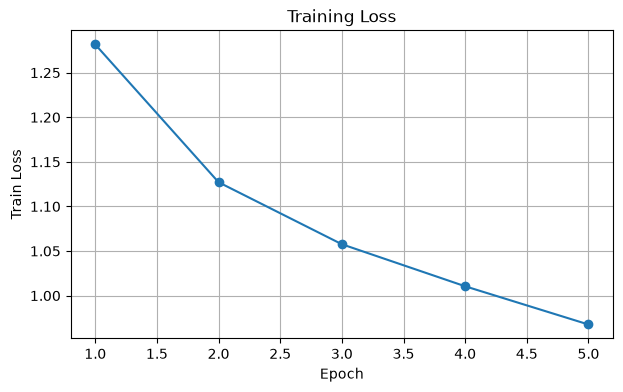

In [9]:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure(figsize=(7, 4))
  plt.plot(range(1, EPOCH + 1), loss_history, marker="o")
  plt.xlabel("Epoch")
  plt.ylabel("Train Loss")
  plt.title("Training Loss")
  plt.grid()

#### STEP 5. 테스트 및 그래프

In [64]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)

Accuracy(load_model, test_DL, 'Test')
Accuracy(load_model, train_DL, 'Train')
print(count_params(load_model))

Test Accuracy : 1630 / 2996 (54.4 %)
Train Accuracy : 2446 / 3521 (69.5 %)
6458758


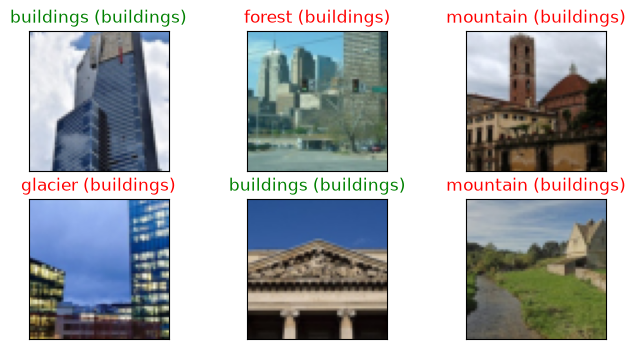

In [65]:
Test_plot(load_model,test_DL)

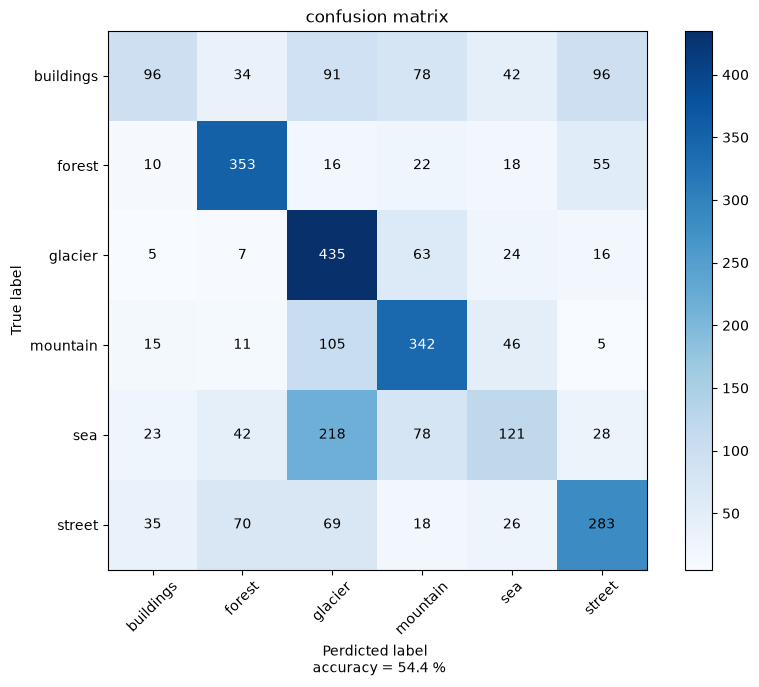

In [66]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45);

#### STEP 7. 모델 파라미터 개수 확인

In [67]:
count_params(model)

6458758

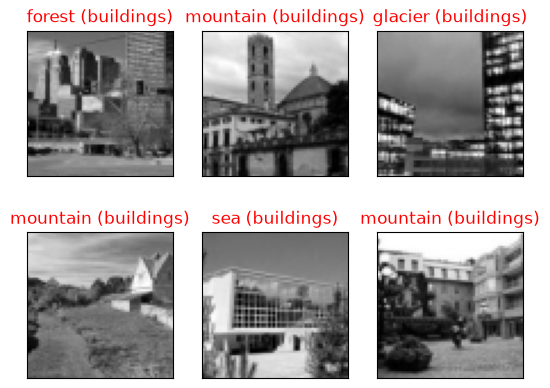

In [68]:
cnt = 0
load_model.eval()

with torch.no_grad():
  for x_batch, y_batch in test_DL :
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    false_idx = pred != y_batch
    X_false = x_batch[false_idx,...].to('cpu')
    pred_false = pred[false_idx,...].to('cpu')
    Y_false = y_batch[false_idx,...].to('cpu')

    if X_false.shape[0] != 0:
      if cnt == 6:
        break
      for i in range(X_false.shape[0]):
        cnt += 1
        pred_class = pred_false[i].item()
        true_class = Y_false[i].item()

        pred_name = test_DS.classes[pred_class]
        ture_name = test_DS.classes[true_class]

        plt.subplot(2,3, cnt, xticks=[], yticks=[])
        plt.imshow(X_false[i,0,...], cmap='gray')
        plt.title(f'{pred_name} ({ture_name})', color='r')
        if cnt == 6:
          break